# PROBLEMA 3: Classificação de Qualidade de Vinhos Utilizando 𝑘 -NN

Nesse projeto, devo **construir um modelo de classificação de vinhos em três categorias de qualidade (baixa, media, alta) a partir de um conjunto de dados químicos utilizando k-NN**.

# Coisas que devo fazer com o Dataset 

1. Preparação dos dados: carregue o dataset e recodifique a variável quality em três classes: notas ≤ 5 como ruim, 6–7 como médio e ≥ 8 como bom. Em seguida, normalize todos os atributos utilizando Min-Max ou 𝑍-score. Justifique por que a normalização é uma etapa obrigatória para o 𝑘-NN.

2.  Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para  garantir que a proporção das três classes seja mantida em ambos os conjuntos.

3.  Treinamento e escolha do 𝑘: treine o modelo para diferentes valores de 𝑘 (ex: 1, 3, 5, 7, 11) utilizando validação  cruzada de 5 folds sobre o conjunto de treino. Plote a acurácia média em função de 𝑘 e escolha o valor com  melhor desempenho. O que acontece com o modelo para valores muito baixos e muito altos de 𝑘?

4. Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: Entre quais classes o modelo erra com mais frequência

In [ ]:
# importando as bibliotecas iniciais 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [97]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 

# juntando as colunas de features + target
df = pd.concat([X,y], axis= 1)

df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 0. Etapa de Pré-processamento e EDA

Não está incluso nas tarefas, mas para responder melhor às questões, decidi dar uma olhada no comportamento dos dados previamente para verificar se existe a necessidade de pré-processamento ou EDA. Já que haverá uma recodificação da variável target na tarefa 1, vou **verificar a distribuição das classes** na variável target `quality` somente após a recodificação.

In [98]:
# verificando se existem valores ausentes no dataset 
print("Valores vazios no conjunto de features X: ",X.isna().sum())
print("Valores vazios na coluna target y: ",y.isna().sum())

Valores vazios no conjunto de features X:  fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64
Valores vazios na coluna target y:  quality    0
dtype: int64


## 1. Preparação dos dados: carregue o dataset e recodifique a variável quality em três classes: notas ≤ 5 como ruim, 6–7 como médio e ≥ 8 como bom. Em seguida, normalize todos os atributos utilizando Min-Max ou 𝑍-score. Justifique por que a normalização é uma etapa obrigatória para o 𝑘-NN.

O dataset já foi carregado logo acima. Agora a variável target `quality` será recodificada logo abaixo: 

Foi criada uma função para categorizar a qualidade dos vinhos de acordo com o seguinte critério:

- notas <= 5 recebem o rótulo `ruim`
- notas 6 e 7 recebem o rótulo `medio`
- notas >= 8 recebem o rótulo `bom`

Depois disso, essa função é aplicada em cada amostra da coluna target `quality` e, em seguida, a nova coluna recodificada `y` é adicionada ao dataframe inicial.

In [99]:
def categorizar_qualidade(nota):
    if(nota <= 5):
        return 'ruim'
    elif(nota == 6 or nota == 7):
        return 'medio'
    elif(nota >= 8):
        return 'bom'
    else:
        raise ValueError("Erro referente ao valor da amostra")


y_cat = y['quality'].apply(categorizar_qualidade)
df['quality'] = y_cat

df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,ruim
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,ruim
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,ruim
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,medio
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,ruim


In [100]:
# distribuição das classes da variável target
contagem = y_cat.value_counts()
percentual = y_cat.value_counts(normalize=True) * 100

print("\nQuantidade de amostras por classe:")
print(contagem)
print("\nPercentual de amostras por classe (%):")
print(percentual.round(2))


Quantidade de amostras por classe:
quality
medio    3915
ruim     2384
bom       198
Name: count, dtype: int64

Percentual de amostras por classe (%):
quality
medio    60.26
ruim     36.69
bom       3.05
Name: proportion, dtype: float64


Podemos observar que a distribuição de classes na variável target é fortemente desbalanceada. Com apenas 3% das amostras sendo classificadas como "bom". Será necessário futuramente tomar decisões para melhorar essa questão, uma vez que com uma quantidade tão baixa de amostras com rótulo `bom`, o modelo não irá conseguir classificar a qualidade do vinho como boa e tenderá a realizar a predição da classe majoritária `medio` ou, em outros casos, optar pela classe `ruim`.

---

Antes de realizar a normalização dos dados, vamos verificar se o algoritmo realmente precisa da normalização visualizando por meio do boxplot como ficam as diferentes escalas das features:

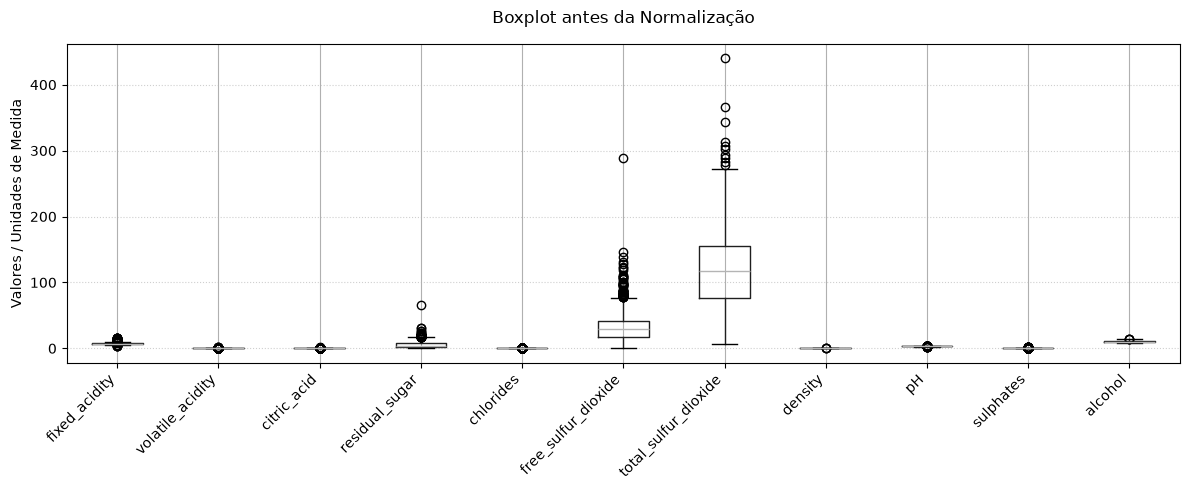

In [101]:
plt.figure(figsize=(12, 5))
X.boxplot()

plt.title('Boxplot antes da Normalização', fontsize=12, pad=15)
plt.ylabel('Valores / Unidades de Medida', fontsize=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Como podemos visualizar pelo boxplot, as features operam em ordens de grandeza muito distintas: variáveis como `total_sulfur_dioxide` (chegando a 440) e `free_sulfur_dioxide` (chegando a quase 300) achatam visual e matematicamente variáveis que operam em frações decimais, como `density` (entre 0.98 e 1.03), `chlorides` e `volatile_acidity`.

Isso é crítico para o aprendizado do modelo por que como o algoritmo do $k$-NN classifica novos pontos calculando a distância geométrica até seus vizinhos mais próximos no espaço vetorial, as variáveis com magnitudes numéricas elevadas dominariam a soma quadrática das distâncias, tornando as variáveis de menor escala irrelevantes, independentemente de sua importância química real.

Tendo essa análise em mente, vamos aplicar a normalização de escala utilizando o `StandardScaler()` do scikit-learn para padronizar as features (Z-score), centralizando-as na média 0 com desvio padrão 1.

In [102]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled,  columns= X.columns)

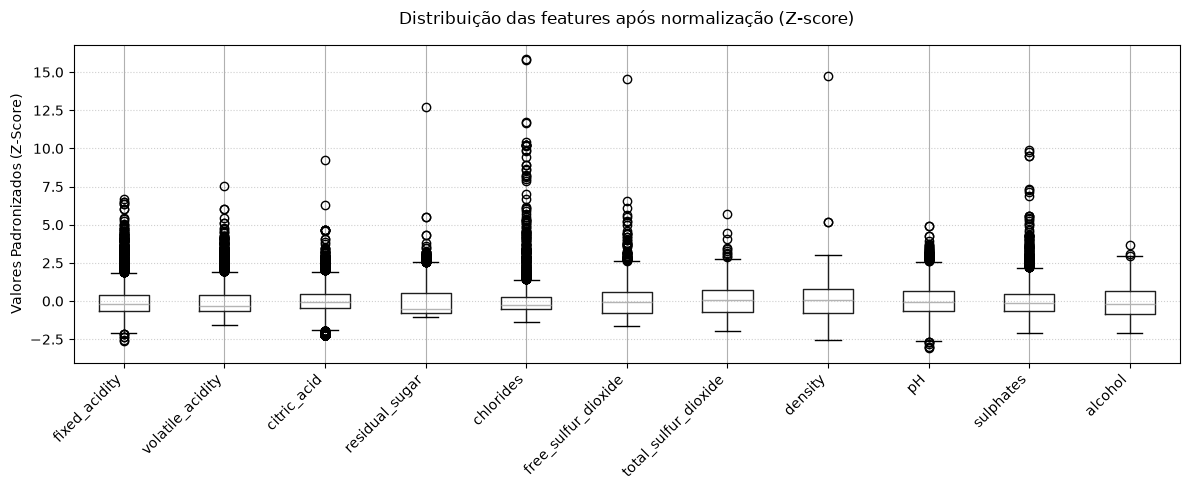

In [103]:
plt.figure(figsize=(12, 5))
X_scaled_df.boxplot()

plt.title('Distribuição das features após normalização (Z-score)', fontsize=12, pad=15)
plt.ylabel('Valores Padronizados (Z-Score)', fontsize=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Podemos observar agora que está tudo normalizado!

## 2.  Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para  garantir que a proporção das três classes seja mantida em ambos os conjuntos.


Vale mencionar que o uso do `stratify` será interessante aqui durante o split dos dados pelo fato das classes da variável `target` estarem mal distribuidas.

In [104]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled,y_cat,random_state=42,test_size= 0.2, stratify= y_cat)

print('Quantidade de amostras de treino: ', X_train.shape[0])
print('Quantidade de amostras de teste:', X_test.shape[0])

Quantidade de amostras de treino:  5197
Quantidade de amostras de teste: 1300


## 3.  Treinamento e escolha do 𝑘: treine o modelo para diferentes valores de 𝑘 (ex: 1, 3, 5, 7, 11) utilizando validação  cruzada de 5 folds sobre o conjunto de treino. Plote a acurácia média em função de 𝑘 e escolha o valor com  melhor desempenho. O que acontece com o modelo para valores muito baixos e muito altos de 𝑘?

Será criado um laço for que irá percorrer cada um dos valores k que serão utilizados para a validação cruzada com 5 folds (`cv= 5`). Dentro desse laço, cada vez que um k vizinho for iterado:

1. O modelo será instanciado 
2. O score de validação cruzada será aplicado utilizando a métrica de validação `accuracy` como medida
3. A partir da validação cruzada, é possível extrair a acurácia média e desvio padrão para aquele k vizinho
4. As acurácias médias e o desvio padrão respectivo serão salvos nos seus respectivos arrays 
5. No final, um print é utilizado para escrever uma log dizendo a acurácia média e o desvio padrão respectivo

In [105]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# valores de k a serem testados
k_values = [1,2,3,4,5,6,7,8,9,10,11,15,21,31,41,51,61]

acuracias_medias = []
desvios_padrao = []

print("Validação Cruzada")

for k in k_values:
    # instância um modelo knn com k vizinhos próximos
    knn = KNeighborsClassifier(n_neighbors= k)

    # aplicando validação cruzada com 5 folds no conjunto de treino
    scores = cross_val_score(knn, X_train, y_train, cv= 5, scoring= 'accuracy')

    # capturando a média e o desvio padrão do respectivo k
    media = scores.mean()
    desvio = scores.std()

    # adicionando as métricas 
    acuracias_medias.append(media)
    desvios_padrao.append(desvio)

    print(f"k = {k:2d} | Acurácia Média = {media:.4f} (+/- {desvio:.4f})")

Validação Cruzada
k =  1 | Acurácia Média = 0.7331 (+/- 0.0088)
k =  2 | Acurácia Média = 0.6966 (+/- 0.0094)
k =  3 | Acurácia Média = 0.7087 (+/- 0.0117)
k =  4 | Acurácia Média = 0.7029 (+/- 0.0129)
k =  5 | Acurácia Média = 0.7125 (+/- 0.0124)
k =  6 | Acurácia Média = 0.7058 (+/- 0.0115)
k =  7 | Acurácia Média = 0.7098 (+/- 0.0096)
k =  8 | Acurácia Média = 0.7064 (+/- 0.0113)
k =  9 | Acurácia Média = 0.7133 (+/- 0.0046)
k = 10 | Acurácia Média = 0.7098 (+/- 0.0073)
k = 11 | Acurácia Média = 0.7146 (+/- 0.0038)
k = 15 | Acurácia Média = 0.7175 (+/- 0.0071)
k = 21 | Acurácia Média = 0.7173 (+/- 0.0103)
k = 31 | Acurácia Média = 0.7220 (+/- 0.0108)
k = 41 | Acurácia Média = 0.7158 (+/- 0.0132)
k = 51 | Acurácia Média = 0.7131 (+/- 0.0121)
k = 61 | Acurácia Média = 0.7121 (+/- 0.0137)


A partir dos arrays que registram as métricas dos k-vizinhos com o passar do tempo. É possível fazer duas coisas:

1. Identificar o melhor k
2. Verificar o desempenho do k-NN por validação cruzada plotando a curva de acurácias médias com o aumento de k-vizinhos

In [106]:
# identificando o melhor k automaticamente
melhor_idx = np.argmax(acuracias_medias)
melhor_k = k_values[melhor_idx]
melhor_acuracia = acuracias_medias[melhor_idx]

print(f"Melhor k: {melhor_k} com Acurácia Média de {melhor_acuracia * 100:.2f}%")

Melhor k: 1 com Acurácia Média de 73.31%


Podemos observar que o melhor k apresentado pela validação é o **k = 1**, obtendo a melhor média nos folds (~$73,31\%$)

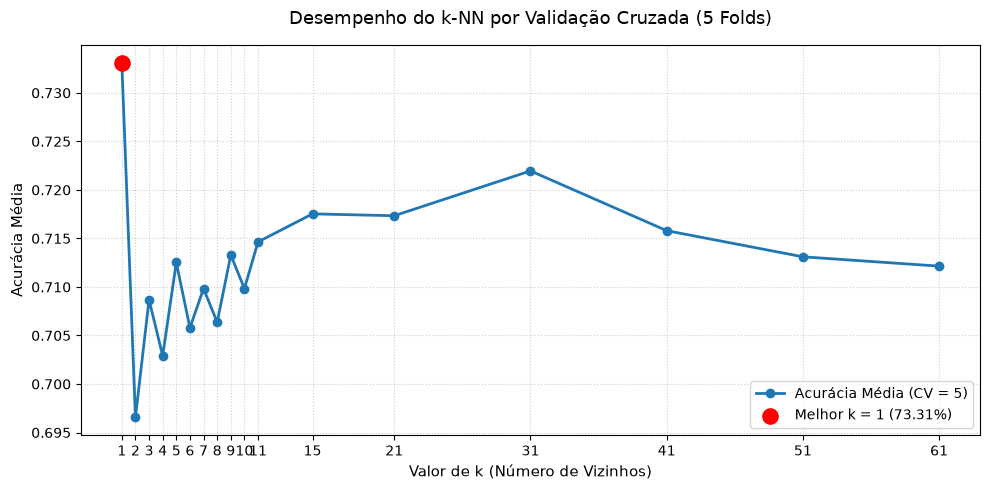

In [107]:
plt.figure(figsize=(10, 5))

# plotando da linha de acurácia
plt.plot(k_values, acuracias_medias, marker='o', color='#1f77b4', linewidth=2, label='Acurácia Média (CV = 5)')

# destacando o melhor k no gráfico
plt.scatter(melhor_k, melhor_acuracia, color='red', s=120, zorder=5, label=f'Melhor k = {melhor_k} ({melhor_acuracia*100:.2f}%)')

plt.title('Desempenho do k-NN por Validação Cruzada (5 Folds)', fontsize=13, pad=15)
plt.xlabel('Valor de k (Número de Vizinhos)', fontsize=11)
plt.ylabel('Acurácia Média', fontsize=11)
plt.xticks(k_values)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

Antes de escolher o hiperparâmetro k no algoritmo do k-NN, temos que ver como a quantidade de k's reflete diretamente o dilema do **tradeoff do viés e da variância**. Isso acontece:

**1. Ao selecionar valores muito baixos de k:**

Com valores muito baixos de k, a tendência é que o algoritmo apresente **alta variância** e, consequentemente, o risco de overfitting, pois o modelo decide a classe com base exclusivamente de poucos vizinhos na proximidade. Isso não é muito interessante tendo em vista que o algorítmo acaba se tornando **muito sensível a ruídos**, pois com poucos k-vizinhos nas proximidades, se houver alguma amostra ruidosa ou um outlier, o modelo fará a predição de forma errada.

**2. Ao selecionar valores muito altos de k:**

Com valores mais altos de k, a tendência é que o algoritmo apresente **alto viés** e, consequentemente, o risco de underfitting, pois o modelo considera uma quantidade k-vizinhos excessivamente grande, diluindo as características locais dos dados.

Consequentemente, como a classe `medio` representa mais de 60% dos rótulos do conjunto de dados, um valor k elevado faria com que as amostras com `medio` vençam todas as votações por maioria. 

---

Nesse sentido, visualizamos por meio do gráfico de desempenho do k-NN que $k = 1$ obteve a maior acurácia média nos folds (~$73,31\%$). Todavia, por mais que o $k = 1$ tenha tido a melhor média, ele acaba se tornando um valor que tem um risco forte de ter overfitting. 

## 4. Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: Entre quais classes o modelo erra com mais frequência

Primeiramente, vamos realizar a inferência do modelo k-NN utilizando o conjunto de teste. Em seguida, aplicaremos as métricas exigidas para enfim responder entre quais classes o modelo erra com mais frequência.

Vale mencionar que o modelo ainda não havia sido treinado de forma definitiva; ele será ajustado agora utilizando o melhor k obtido na questão anterior

In [108]:
knn_final = KNeighborsClassifier(n_neighbors= melhor_k)
knn_final.fit(X_train, y_train)
y_pred = knn_final.predict(X_test)

In [109]:
from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support

# ordem padronizada das classes em array 
classes = ['ruim', 'medio', 'bom']

# acurácia global
acuracia_teste = accuracy_score(y_test, y_pred)
print(f"Acurácia Geral no Teste: {acuracia_teste * 100:.2f}%\n")

# métricas por classe
precisao, recall, f1, suporte = precision_recall_fscore_support(y_test, y_pred, labels=classes)

# criando uma tabela para visualização clara das métricas por classe
df_metricas = pd.DataFrame({
    'Precisão': precisao,
    'Recall': recall,
    'F1-Score': f1,
    'Total de Amostras (Suporte)': suporte
}, index=classes)

print("Métricas detalhadas por classe:")
display(df_metricas.round(4))

print("\nRelatório de classificação completo:")
print(classification_report(y_test, y_pred, labels=classes, target_names=classes))

Acurácia Geral no Teste: 76.92%

Métricas detalhadas por classe:


,Precisão,Recall,F1-Score,Total de Amostras (Suporte)
ruim,0.7277,0.7170,0.7223,477
medio,0.8045,0.8148,0.8096,783
bom,0.5405,0.5000,0.5195,40



Relatório de classificação completo:
              precision    recall  f1-score   support

        ruim       0.73      0.72      0.72       477
       medio       0.80      0.81      0.81       783
         bom       0.54      0.50      0.52        40

    accuracy                           0.77      1300
   macro avg       0.69      0.68      0.68      1300
weighted avg       0.77      0.77      0.77      1300



<Figure size 600x500 with 0 Axes>

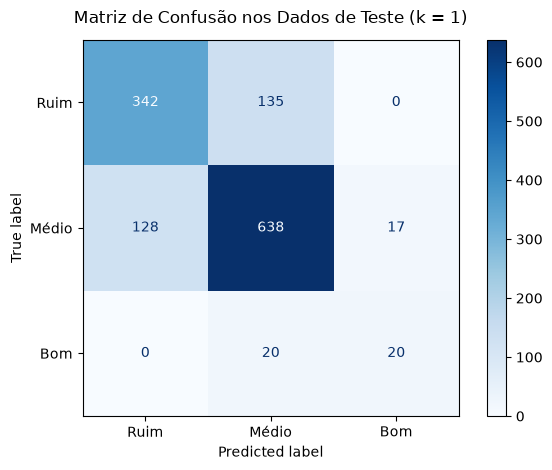

In [110]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred,
    labels=classes,
    display_labels=['Ruim', 'Médio', 'Bom'],
    cmap='Blues'
)

plt.title(f'Matriz de Confusão nos Dados de Teste (k = {melhor_k})', fontsize=12, pad=12)
plt.grid(False)

plt.tight_layout()
plt.show()

A partir da matriz de confusão e do relatório de métricas, podemos responder à pergunta entre quais classes o modelo erra com mais frequência sob duas perspectivas:

#### 1. Em termos de volume absoluto de casos:

O maior volume absoluto de confusões ocorre entre as classes adjacentes `ruim` e `medio`, totalizando 263 erros ($135$ vinhos ruins classificados como médios e $128$ vinhos médios classificados como ruins). Esse volume elevado se deve ao fato de que ambas as classes concentram quase $97\%$ de todas as amostras do conjunto de dados e compartilham fronteiras físico-químicas contínuas (diferença sutil entre notas 5 e 6). Entre os extremos `ruim` e `bom`, o modelo cometeu zero erros.

#### 2. Em termos de proporção e taxa de erro relativo:

Em nível proporcional por classe, o pior desempenho de predição ocorreu na classe `bom`:

- **Recall de 50,0% (Taxa de omissão de 50%):** O modelo errou exatamente metade de todos os vinhos verdadeiramente bons da base de teste ($20$ acertos e $20$ erros de classificação como `medio`).

- **Precisão de 54,05%:** Das 37 vezes em que o modelo previu a classe `bom`, em 17 delas o vinho era apenas `medio`.

- **Menor F1-Score (0,52):** Em contraste com $0,81$ (`medio`) e $0,72$ (`ruim`), a classe `bom` sofreu fortemente com o severo desbalanceamento amostral ($3\%$ do dataset).

---

Como o melhor parâmetro encontrado foi $k = 1$, o classificador decide o rótulo olhando apenas 1 vizinho mais próximo no espaço vetorial. Por ser a classe minoritária em um dataset desbalanceado, a probabilidade de uma amostra de teste ter como único vizinho mais próximo um ponto da classe `bom` é reduzida, fazendo com que sua vizinhança seja frequentemente "engolida" pela densidade da classe majoritária `medio`.